# Chapitre 6 - Lab : réplication en streaming avec PostgreSQL

Les cours 1 et 2 ont simulé un leader et ses suiveurs. Ce lab observe la même chose sur
un vrai système : un primaire PostgreSQL 16 et deux répliques alimentées par l'expédition
du WAL (*streaming replication*). On y mesure le retard de réplication, on provoque une
lecture périmée, on implémente « lire ses écritures » avec un jeton de position, on
compare les niveaux de `synchronous_commit` et on voit un suiveur synchrone bloquer les
écritures, on lit le journal logique produit par `test_decoding`, et l'on termine par un
basculement qui perd des écritures confirmées puis par un split brain.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/replication/compose.yml -p ddia_replication up -d
# ... exécuter le notebook (une seule fois : la fin modifie la topologie) ...
docker compose -f docker/replication/compose.yml -p ddia_replication down -v
```

Chaque réplique démarre par une copie de base du primaire (`pg_basebackup -R` :
instantané + position du journal, puis mode standby), exactement la recette de la
section *Setting Up New Followers*. Ports de l'hôte : primaire **10632**, `replica1`
**10633**, `replica2` **10634** (utilisateur, mot de passe et base : `ddia`).

**Plan.**

1. La topologie : un primaire, deux répliques en lecture seule.
2. Mesurer le retard de réplication.
3. Lecture périmée et « lire ses écritures » avec un jeton de LSN.
4. Réplication synchrone : coût et blocage.
5. Le journal logique.
6. Basculement : écritures perdues et split brain.

In [1]:
import subprocess
import threading
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg import errors

from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.max_colwidth", 90)
ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (d / "docker/replication/compose.yml").exists())
COMPOSE = ["docker", "compose", "-f", str(ROOT / "docker/replication/compose.yml"), "-p", "ddia_replication"]
PORTS = {"primary": 10632, "replica1": 10633, "replica2": 10634}
DSN = {n: f"host=localhost port={p} user=ddia password=ddia dbname=ddia connect_timeout=5" for n, p in PORTS.items()}

def compose(*args):
    return subprocess.run(COMPOSE + list(args), check=True, capture_output=True, text=True)

def q(node, sql, params=None):
    with psycopg.connect(DSN[node], autocommit=True) as c:
        cur = c.execute(sql, params)
        return cur.fetchall() if cur.description else None

def attendre(node, timeout=60):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            return q(node, "SELECT 1")
        except psycopg.OperationalError:
            time.sleep(0.5)
    raise RuntimeError(f"{node} injoignable")

for n in PORTS:
    attendre(n)
print(q("primary", "SELECT version()")[0][0])

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (Alpine 15.2.0) 15.2.0, 64-bit


## 1. La topologie (section *Single-Leader Replication*)

Côté primaire, la vue `pg_stat_replication` liste les suiveurs connectés, leur état et
les positions (LSN) qu'ils ont reçues, écrites sur disque et rejouées. Côté répliques,
`pg_is_in_recovery()` vaut vrai : elles rejouent le journal et refusent les écritures.

In [2]:
for _ in range(60):
    if len(q("primary", "SELECT 1 FROM pg_stat_replication")) == 2:
        break
    time.sleep(1)
display(pd.DataFrame(q("primary", """SELECT application_name, state, sync_state, sent_lsn::text, replay_lsn::text
                                      FROM pg_stat_replication ORDER BY application_name"""),
                     columns=["suiveur", "état", "mode", "LSN envoyé", "LSN rejoué"]))
display(pd.DataFrame([(n, q(n, "SELECT pg_is_in_recovery()")[0][0]) for n in PORTS],
                     columns=["nœud", "en récupération (lecture seule)"]).set_index("nœud"))
q("primary", "DROP TABLE IF EXISTS mesures; CREATE TABLE mesures (id bigserial PRIMARY KEY, v int, t timestamptz DEFAULT now())")
time.sleep(1)
try:
    q("replica1", "INSERT INTO mesures (v) VALUES (1)")
except errors.ReadOnlySqlTransaction as e:
    print("écriture sur replica1 refusée :", e.diag.message_primary)

,suiveur,état,mode,LSN envoyé,LSN rejoué
0,replica1,streaming,async,0/4000000,0/4000000
1,replica2,streaming,async,0/4000000,0/4000000


,en récupération (lecture seule)
nœud,
primary,False
replica1,True
replica2,True


écriture sur replica1 refusée : cannot execute INSERT in a read-only transaction


Les deux suiveurs sont en `streaming`, en mode `async` (réglage par défaut) ; la table
créée sur le primaire est apparue sur les répliques par le journal, et une écriture
directe sur une réplique est refusée : les suiveurs sont en lecture seule pour les
clients.

> **À retenir.** PostgreSQL réalise la réplication à leader unique par expédition du WAL ;
> `pg_stat_replication` expose, pour chaque suiveur, les positions du journal qui
> permettent de mesurer son retard.

## 2. Mesurer le retard de réplication (section *Problems with Replication Lag*)

Pour chaque écriture validée sur le primaire, on interroge `replica2` en boucle jusqu'à
voir la ligne : le délai mesuré est le retard **perçu** par un lecteur. On le fait d'abord
à vide, puis pendant qu'un autre client écrit en masse (des insertions de 200 000 lignes).

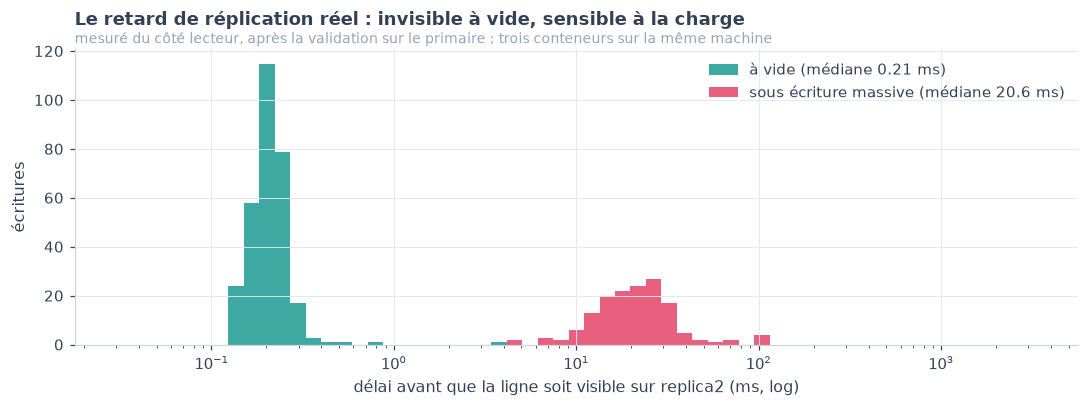

,à vide,sous charge
p50 (ms),0.21,20.65
p99 (ms),0.48,96.70
max (ms),3.64,109.54


In [3]:
def mesurer(n=200, charge=False):
    stop = threading.Event()
    def ecrivain_massif():
        with psycopg.connect(DSN["primary"], autocommit=True) as c:
            c.execute("CREATE TABLE IF NOT EXISTS lest (x int, pad text)")
            while not stop.is_set():
                c.execute("INSERT INTO lest SELECT g, repeat('x', 200) FROM generate_series(1, 200000) g")
    th = threading.Thread(target=ecrivain_massif, daemon=True)
    if charge:
        th.start(); time.sleep(1.0)
    delais = []
    with psycopg.connect(DSN["primary"], autocommit=True) as p, psycopg.connect(DSN["replica2"], autocommit=True) as r:
        for i in range(n):
            pid = p.execute("INSERT INTO mesures (v) VALUES (%s) RETURNING id", (i,)).fetchone()[0]
            t0 = time.perf_counter()
            while not r.execute("SELECT 1 FROM mesures WHERE id = %s", (pid,)).fetchone():
                pass
            delais.append((time.perf_counter() - t0) * 1000)
    stop.set()
    if charge:
        th.join()
    return np.array(delais)

a_vide = mesurer(300)
sous_charge = mesurer(150, charge=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(-1.5, 3.5, 60)
ax.hist(a_vide, bins=bins, color=TEAL, alpha=0.8, label=f"à vide (médiane {np.median(a_vide):.2f} ms)")
ax.hist(sous_charge, bins=bins, color=ROSE, alpha=0.7, label=f"sous écriture massive (médiane {np.median(sous_charge):.1f} ms)")
ax.set_xscale("log"); ax.set_xlabel("délai avant que la ligne soit visible sur replica2 (ms, log)"); ax.set_ylabel("écritures")
ax.set_title("Le retard de réplication réel : invisible à vide, sensible à la charge")
subtitle(ax, "mesuré du côté lecteur, après la validation sur le primaire ; trois conteneurs sur la même machine")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"à vide": np.percentile(a_vide, [50, 99, 100]), "sous charge": np.percentile(sous_charge, [50, 99, 100])},
             index=["p50 (ms)", "p99 (ms)", "max (ms)"]).round(2)

Sur une même machine, à vide, la ligne est visible sur la réplique en une fraction de
milliseconde (souvent dès la première lecture) : c'est le cas normal du livre, un retard
imperceptible. Sous écriture massive, le journal à transmettre et à rejouer s'allonge, et
la même petite écriture attend derrière les autres (le journal se rejoue **dans
l'ordre**) : le retard grimpe de plusieurs ordres de grandeur. Le primaire mesure aussi
le retard en **octets de journal** et en temps :

In [4]:
q("primary", "INSERT INTO lest SELECT g, repeat('x', 200) FROM generate_series(1, 300000) g")
display(pd.DataFrame(q("primary", """SELECT application_name, pg_wal_lsn_diff(pg_current_wal_lsn(), replay_lsn) AS octets,
                                             write_lag, replay_lag FROM pg_stat_replication ORDER BY 1"""),
                     columns=["suiveur", "retard (octets de WAL)", "write_lag", "replay_lag"]))
q("primary", "DROP TABLE IF EXISTS lest")

,suiveur,retard (octets de WAL),write_lag,replay_lag
0,replica1,79173632,0 days 00:00:00.001333,0 days 00:00:00.001333
1,replica2,79432832,0 days 00:00:00.000791,0 days 00:00:00.000791


Juste après une grosse insertion, le retard en octets est non nul : c'est la soustraction
« position du leader moins position du suiveur » décrite dans la section *Monitoring
staleness*, que l'on surveille et sur laquelle on déclenche des alertes.

> **À retenir.** Le retard de réplication se mesure en positions de journal (octets) ou
> en temps ; négligeable à vide, il dépend de la charge d'écriture, car le suiveur rejoue
> le journal dans l'ordre.

## 3. Lecture périmée et « lire ses écritures » (section *Reading Your Own Writes*)

Pour rendre le retard visible à coup sûr, on **suspend le rejeu** du journal sur
`replica1` (`pg_wal_replay_pause()`) : la réplique continue de recevoir le journal mais ne
l'applique plus, comme un suiveur saturé. Un utilisateur écrit un commentaire sur le
primaire, puis relit.

In [5]:
q("primary", "DROP TABLE IF EXISTS commentaires; CREATE TABLE commentaires (id serial PRIMARY KEY, auteur text, texte text)")
time.sleep(0.5)
q("replica1", "SELECT pg_wal_replay_pause()")
with psycopg.connect(DSN["primary"], autocommit=True) as p:
    p.execute("INSERT INTO commentaires (auteur, texte) VALUES ('alice', 'Premier !')")
    jeton = p.execute("SELECT pg_current_wal_lsn()::text").fetchone()[0]     # position après l'écriture
print("jeton (LSN de l'écriture) :", jeton)
pd.DataFrame({"nœud": ["primary", "replica1 (rejeu suspendu)", "replica2"],
              "commentaires visibles": [q("primary", "SELECT count(*) FROM commentaires")[0][0],
                                        q("replica1", "SELECT count(*) FROM commentaires")[0][0],
                                        q("replica2", "SELECT count(*) FROM commentaires")[0][0]],
              "LSN rejoué": ["-", q("replica1", "SELECT pg_last_wal_replay_lsn()::text")[0][0],
                             q("replica2", "SELECT pg_last_wal_replay_lsn()::text")[0][0]]}).set_index("nœud")

jeton (LSN de l'écriture) : 0/80B56C60


,commentaires visibles,LSN rejoué
nœud,,
primary,1,-
replica1 (rejeu suspendu),0,0/80B56AD8
replica2,1,0/80B56C60


Alice ne voit pas son commentaire si sa relecture tombe sur `replica1`. Implémentons la
parade du jeton : le client garde le LSN de sa dernière écriture ; pour lire, il choisit
une réplique dont la position rejouée est au moins égale au jeton, sinon il attend un peu,
sinon il lit sur le primaire.

In [6]:
def lire_ses_ecritures(sql, jeton, repliques=("replica1", "replica2"), attente=0.2):
    for nom in repliques:
        with psycopg.connect(DSN[nom], autocommit=True) as c:
            t0 = time.time()
            while time.time() - t0 < attente:
                ok = c.execute("SELECT pg_last_wal_replay_lsn() >= %s::pg_lsn", (jeton,)).fetchone()[0]
                if ok:
                    return nom, c.execute(sql).fetchall()
                time.sleep(0.01)
    return "primary", q("primary", sql)

for ordre in [("replica1", "replica2"), ("replica1",)]:
    noeud, res = lire_ses_ecritures("SELECT auteur, texte FROM commentaires", jeton, ordre)
    print(f"répliques candidates {ordre} -> lecture servie par {noeud} : {res}")
q("replica1", "SELECT pg_wal_replay_resume()")
time.sleep(0.5)
print("après reprise du rejeu, replica1 voit :", q("replica1", "SELECT count(*) FROM commentaires")[0][0], "commentaire(s)")

répliques candidates ('replica1', 'replica2') -> lecture servie par replica2 : [('alice', 'Premier !')]


répliques candidates ('replica1',) -> lecture servie par primary : [('alice', 'Premier !')]


après reprise du rejeu, replica1 voit : 1 commentaire(s)


Avec les deux répliques candidates, la lecture est servie par `replica2`, à jour ; si
seule `replica1` est candidate, elle échoue à atteindre le jeton dans le délai et la
lecture part au primaire. Dans les deux cas, Alice voit son commentaire. Une fois le rejeu
repris, `replica1` rattrape instantanément (elle avait reçu le journal, elle ne l'appliquait
plus).

> **À retenir.** Un jeton de LSN suffit à garantir « lire ses écritures » sur PostgreSQL :
> `pg_current_wal_lsn()` après l'écriture, `pg_last_wal_replay_lsn()` sur la réplique.

## 4. Réplication synchrone : coût et blocage (section *Synchronous Versus Asynchronous Replication*)

On désigne `replica1` comme suiveur synchrone (`synchronous_standby_names`). Le paramètre
`synchronous_commit`, réglable par transaction, dit alors ce qu'attend une validation :

- `off` : rien, pas même l'écriture du WAL local sur disque (risque de perte locale) ;
- `local` : le WAL local sur disque, pas le suiveur (asynchrone) ;
- `remote_write` : le suiveur a reçu et écrit le WAL (sans forcer le disque) ;
- `on` : le suiveur a écrit **et** forcé le WAL sur disque ;
- `remote_apply` : le suiveur l'a **rejoué** (une lecture sur lui verra l'écriture).

Mesurons la latence de 300 validations pour chaque niveau.

,suiveur,mode
0,replica1,sync
1,replica2,async


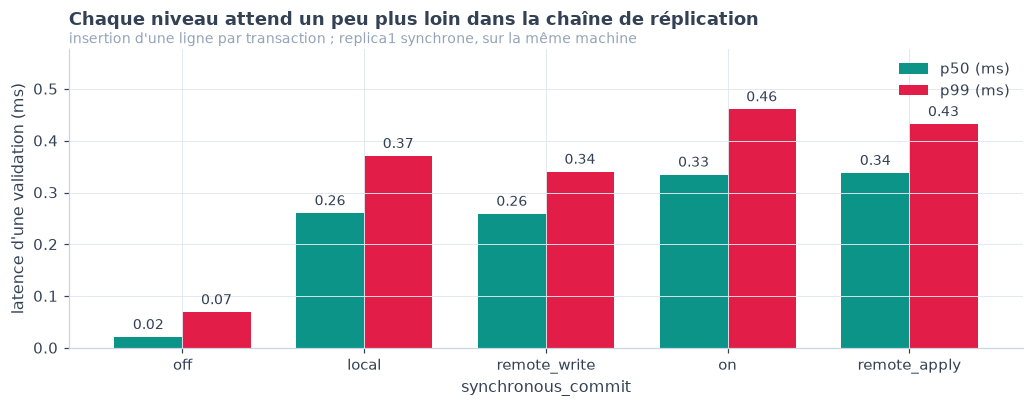

,p50 (ms),p99 (ms)
off,0.021,0.069
local,0.261,0.371
remote_write,0.259,0.340
on,0.335,0.461
remote_apply,0.338,0.432


In [7]:
q("primary", "ALTER SYSTEM SET synchronous_standby_names = 'replica1'")
q("primary", "SELECT pg_reload_conf()")
time.sleep(1.5)
display(pd.DataFrame(q("primary", "SELECT application_name, sync_state FROM pg_stat_replication ORDER BY 1"),
                     columns=["suiveur", "mode"]))
niveaux = ["off", "local", "remote_write", "on", "remote_apply"]
lat = {}
with psycopg.connect(DSN["primary"], autocommit=True) as c:
    for niv in niveaux:
        c.execute(f"SET synchronous_commit = {niv}")
        ts = []
        for i in range(300):
            t0 = time.perf_counter()
            c.execute("INSERT INTO mesures (v) VALUES (%s)", (i,))
            ts.append((time.perf_counter() - t0) * 1000)
        lat[niv] = np.array(ts)
L = pd.DataFrame({n: [np.median(v), np.percentile(v, 99)] for n, v in lat.items()}, index=["p50 (ms)", "p99 (ms)"]).T
ax = L.plot.bar(figsize=(9.5, 3.8), color=[TEAL, ROSE], rot=0, width=0.75)
annotate_bars(ax, "{:.2f}")
ax.set_ylabel("latence d'une validation (ms)"); ax.set_xlabel("synchronous_commit")
ax.set_ylim(0, L.values.max() * 1.25)
ax.set_title("Chaque niveau attend un peu plus loin dans la chaîne de réplication")
subtitle(ax, "insertion d'une ligne par transaction ; replica1 synchrone, sur la même machine")
plt.tight_layout(); plt.show()
L.round(3)

Même sur une seule machine, la hiérarchie apparaît : `off` est de loin le plus rapide,
`local` paie le vidage du WAL sur disque ; `remote_write` ne coûte guère plus ici (l'envoi
au suiveur, à quelques dizaines de microsecondes, se fait pendant le vidage local), et
`on` et `remote_apply` ajoutent le vidage, puis le rejeu, côté suiveur. Entre deux zones ou deux
régions, l'écart se compterait en millisecondes ou en dizaines de millisecondes.

**Le revers : un suiveur synchrone indisponible bloque les écritures.** Gelons `replica1`
(`docker pause`, l'équivalent d'un nœud qui ne répond plus) et tentons une validation avec
`synchronous_commit = on`.

In [8]:
compose("pause", "replica1")
resultat = {}
def ecriture_bloquee():
    t0 = time.perf_counter()
    with psycopg.connect(DSN["primary"], autocommit=True) as c:
        c.execute("SET synchronous_commit = on")
        c.execute("INSERT INTO commentaires (auteur, texte) VALUES ('bob', 'écrit pendant le gel')")
    resultat["durée"] = time.perf_counter() - t0
th = threading.Thread(target=ecriture_bloquee, daemon=True)
th.start()
time.sleep(3)
attente = q("primary", "SELECT wait_event_type, wait_event, left(query, 60) FROM pg_stat_activity WHERE wait_event = 'SyncRep'")
vue = q("primary", "SELECT count(*) FROM commentaires WHERE auteur = 'bob'")[0][0]
local = None
with psycopg.connect(DSN["primary"], autocommit=True) as c:          # une autre transaction, en mode local
    c.execute("SET synchronous_commit = local")
    t0 = time.perf_counter()
    c.execute("INSERT INTO commentaires (auteur, texte) VALUES ('carole', 'mode local')")
    local = (time.perf_counter() - t0) * 1000
print("après 3 s, la validation de bob est-elle terminée ?", not th.is_alive())
print("sessions en attente de réplication synchrone :", attente)
print("la ligne de bob est-elle visible des autres sessions ?", bool(vue))
print(f"une transaction en synchronous_commit = local passe, elle, en {local:.2f} ms")
compose("unpause", "replica1")
th.join(timeout=30)
print(f"après le dégel, la validation de bob se termine ; elle a duré {resultat['durée']:.1f} s")

après 3 s, la validation de bob est-elle terminée ? False
sessions en attente de réplication synchrone : [('IPC', 'SyncRep', "INSERT INTO commentaires (auteur, texte) VALUES ('bob', 'écr")]
la ligne de bob est-elle visible des autres sessions ? False
une transaction en synchronous_commit = local passe, elle, en 11.21 ms
après le dégel, la validation de bob se termine ; elle a duré 3.1 s


Pendant le gel, la validation de bob reste suspendue sur l'attente `SyncRep` : la ligne
est écrite dans le WAL local mais n'est pas encore confirmée au client ni visible des
autres sessions. Les transactions qui choisissent `local` passent, elles. Dès que
`replica1` répond, la validation se termine. Voilà pourquoi le livre juge impraticable de
rendre tous les suiveurs synchrones, et pourquoi on désigne en pratique plusieurs
candidats (`synchronous_standby_names = 'ANY 1 (replica1, replica2)'` : un quorum, le
semi-synchrone du cours 1). Revenons en asynchrone pour la suite.

In [9]:
q("primary", "ALTER SYSTEM SET synchronous_standby_names = ''")
q("primary", "SELECT pg_reload_conf()")
time.sleep(1)

> **À retenir.** `synchronous_commit` choisit, transaction par transaction, jusqu'où
> attendre (disque local, réception, disque distant, rejeu) ; un suiveur synchrone figé
> suspend les validations qui l'attendent.

## 5. Le journal logique (section *Logical (row-based) log replication*)

PostgreSQL réplique par le WAL physique, mais sait **décoder** ce WAL en événements
logiques (c'est ce qu'utilisent la réplication logique et la capture des changements).
Le module de sortie `test_decoding`, fourni avec PostgreSQL, les affiche en texte. Créons
un slot de réplication logique, exécutons des instructions non déterministes, et lisons
ce qu'elles ont produit.

In [10]:
q("primary", "DROP TABLE IF EXISTS comptes; CREATE TABLE comptes (id int PRIMARY KEY, solde numeric, maj timestamptz)")
q("primary", "INSERT INTO comptes VALUES (1, 100, now()), (2, 50, now()), (3, 10, now())")
q("primary", "SELECT pg_create_logical_replication_slot('lab_slot', 'test_decoding')")
with psycopg.connect(DSN["primary"]) as c:                     # une transaction de trois instructions
    c.execute("UPDATE comptes SET solde = solde * 2, maj = now() WHERE solde > 20")
    c.execute("INSERT INTO comptes VALUES (4, round((random() * 1000)::numeric, 2), clock_timestamp())")
    c.execute("DELETE FROM comptes WHERE id = 3")
changes = q("primary", "SELECT lsn::text, xid, data FROM pg_logical_slot_get_changes('lab_slot', NULL, NULL)")
q("primary", "SELECT pg_drop_replication_slot('lab_slot')")
pd.DataFrame(changes, columns=["LSN", "transaction", "événement logique"])

,LSN,transaction,événement logique
0,0/80BA7DD0,2730,BEGIN 2730
1,0/80BA7DD0,2730,table public.comptes: UPDATE: id[integer]:1 solde[numeric]:200 maj[timestamp with time...
2,0/80BA7E30,2730,table public.comptes: UPDATE: id[integer]:2 solde[numeric]:100 maj[timestamp with time...
3,0/80BA7E90,2730,table public.comptes: INSERT: id[integer]:4 solde[numeric]:284.13 maj[timestamp with t...
4,0/80BA7F20,2730,table public.comptes: DELETE: id[integer]:3
5,0/80BA7F90,2730,COMMIT 2730


Une seule instruction `UPDATE` a produit **un événement par ligne modifiée**, avec les
nouvelles valeurs de toutes les colonnes ; `random()` et `clock_timestamp()` y figurent
déjà évalués ; la suppression ne porte que la clé primaire ; le tout est encadré par
`BEGIN` et `COMMIT`. C'est exactement le format logique décrit dans le livre : un suiveur
ou un système externe peut le rejouer sans rien recalculer.

> **À retenir.** Le décodage logique transforme le WAL physique en événements par ligne,
> aux valeurs figées : la base de la réplication logique et de la capture des changements
> (chapitre 12).

## 6. Basculement : écritures perdues et split brain (section *Leader failure: Failover*)

Scénario du cours 1, sur le vrai système. On coupe le flux de réplication de `replica2`
(on vide son paramètre `primary_conninfo`, l'équivalent d'une coupure réseau entre elle et
le primaire ; geler le conteneur ne suffirait pas, le noyau continuerait de remplir ses
tampons réseau), on valide cinq commandes sur le primaire (le client reçoit « ok » : réplication
asynchrone), puis le primaire meurt brutalement (`docker kill`). On dégèle `replica2` et,
Puis, par erreur ou faute d'information, c'est `replica2` qu'on promeut.

In [11]:
q("primary", "DROP TABLE IF EXISTS commandes; CREATE TABLE commandes (id serial PRIMARY KEY, client text)")
time.sleep(1)
q("replica2", "ALTER SYSTEM SET primary_conninfo = ''")
q("replica2", "SELECT pg_reload_conf()")
time.sleep(2)
print("suiveurs encore connectés au primaire :", q("primary", "SELECT application_name FROM pg_stat_replication"))
with psycopg.connect(DSN["primary"], autocommit=True) as c:
    for i in range(5):
        c.execute("INSERT INTO commandes (client) VALUES (%s)", (f"client{i}",))   # validé, acquitté
confirmees = q("primary", "SELECT count(*) FROM commandes")[0][0]
time.sleep(0.5)
compose("kill", "primary")
time.sleep(2)
positions = pd.DataFrame([(n, q(n, "SELECT pg_last_wal_receive_lsn()::text")[0][0], q(n, "SELECT count(*) FROM commandes")[0][0])
                          for n in ("replica1", "replica2")], columns=["suiveur", "dernier LSN reçu", "commandes"]).set_index("suiveur")
display(positions)
q("replica2", "SELECT pg_promote()")
time.sleep(2)
print("commandes confirmées par l'ancien primaire :", confirmees)
print("replica2 est-elle désormais primaire ?", not q("replica2", "SELECT pg_is_in_recovery()")[0][0])
print("commandes présentes sur le nouveau primaire :", q("replica2", "SELECT count(*) FROM commandes")[0][0])
TIMELINE = "SELECT ('x' || substr(pg_walfile_name(pg_current_wal_lsn()), 1, 8))::bit(32)::int"
print("ligne de temps (timeline) de replica2 :", q("replica2", TIMELINE)[0][0])

suiveurs encore connectés au primaire : [('replica1',)]


,dernier LSN reçu,commandes
suiveur,,
replica1,0/80BB1AE0,5
replica2,0/80BB1680,0


commandes confirmées par l'ancien primaire : 5
replica2 est-elle désormais primaire ? True
commandes présentes sur le nouveau primaire : 0
ligne de temps (timeline) de replica2 : 2


Les cinq commandes avaient été confirmées au client ; le nouveau primaire n'en a aucune.
Le tableau montre pourtant que `replica1` les avait reçues (son LSN est plus grand) :
il fallait promouvoir **le suiveur le plus à jour**, exactement ce que fait le contrôleur
du cours 1. PostgreSQL marque la promotion en ouvrant une nouvelle **ligne de temps**
(timeline 2) : l'historique bifurque à cet endroit.

**Le split brain.** Que se passe-t-il si l'ancien primaire redémarre ? Rien ne lui dit
qu'il a été remplacé : il repart en primaire.

In [12]:
compose("start", "primary")
attendre("primary")
time.sleep(2)
for n in ("primary", "replica2"):
    q(n, "INSERT INTO commandes (client) VALUES (%s)", (f"écrit sur {n}",))
etat = pd.DataFrame([(n, not q(n, "SELECT pg_is_in_recovery()")[0][0], q(n, TIMELINE)[0][0],
                      q(n, "SELECT count(*) FROM commandes")[0][0], q(n, "SELECT string_agg(client, ', ' ORDER BY id) FROM commandes")[0][0])
                     for n in ("primary", "replica2")], columns=["nœud", "accepte les écritures", "timeline", "commandes", "contenu"])
display(etat.set_index("nœud"))
for _ in range(40):                                  # replica1 retente sa connexion toutes les 5 s
    suit = q("replica1", "SELECT sender_host, status FROM pg_stat_wal_receiver")
    if suit:
        break
    time.sleep(0.5)
print("replica1 suit :", suit, "| commandes vues par replica1 :", q("replica1", "SELECT count(*) FROM commandes")[0][0])

,accepte les écritures,timeline,commandes,contenu
nœud,,,,
primary,True,1,6,"client0, client1, client2, client3, client4, écrit sur primary"
replica2,True,2,1,écrit sur replica2


replica1 suit : [('primary', 'streaming')] | commandes vues par replica1 : 6


Deux nœuds acceptent maintenant les écritures, sur deux lignes de temps différentes, avec
des contenus divergents : c'est le split brain. `replica1`, elle, s'est reconnectée à
l'ancien primaire (son adresse n'a pas changé) et suit donc la mauvaise branche. Les
outils de basculement (Patroni, pg_auto_failover...) existent précisément pour éviter
cela : un seul arbitre décide du leader, les clients et les suiveurs sont reconfigurés,
et l'ancien primaire est **clôturé** (fencing) avant de pouvoir revenir, puis reconstruit
en suiveur (par exemple avec `pg_rewind`).

> **À retenir.** Sur un vrai système comme dans la simulation, un basculement asynchrone
> peut jeter des écritures confirmées, surtout si l'on ne promeut pas le suiveur le plus à
> jour ; et sans clôture, l'ancien leader qui revient crée un split brain.

## Pour finir

Le lab a modifié la topologie : pour le rejouer, repartir de zéro.

```bash
docker compose -f docker/replication/compose.yml -p ddia_replication down -v
```

**Synthèse.** Le retard de réplication est négligeable à vide et croît avec la charge ;
un jeton de LSN garantit « lire ses écritures » ; `synchronous_commit` règle, par
transaction, le compromis entre latence et durabilité, et un suiveur synchrone figé
bloque les validations ; le décodage logique expose un journal par lignes aux valeurs
figées ; un basculement mal mené perd des écritures confirmées et peut créer deux
leaders. Les mécanismes de consensus qui rendent l'élection du leader sûre sont l'objet du
chapitre 10.